# Why Monte Carlo Beats TD Learning in Some Partially Observable Environments

## Introduction

Monte Carlo (MC) and temporal-difference (TD) learning are two different approaches to estimating the value function of a policy. MC uses the return observed over an episode, while TD uses the reward from the next step and a bootstrapped estimate of the remaining return. MC does not rely on the Markov property, which often leads to different value estimates. In the case of partially observable environments, MC can sometimes produce more accurate results. 

Let's use a small example to understand why. 

## Let's Construct A Partially Observable Environment

Our environment has two equally likely kinds of episodes. An episode begins at either observation $A$ or observation $C$. Both lead to an observation $B$, followed by a terminal reward. The first transition has reward zero. The environment actually contains two different hidden states behind $B$: one reached from $A$ and another reached from $C$. The agent cannot distinguish them from the current observation alone.

![td_environment](mc_td_environment.png)


We will use an undiscounted return ($\gamma=1$), with no actions to choose, since this is a policy-evaluation problem, not a control problem. Each episode starts at $A$ or $C$ with probability $1/2$.  The value of an observation is the expected return conditioned on it:

$$
v(o)=\mathbb{E}[G_t\mid O_t=o]
$$

The returns from $A$ and $C$ are always $+1$ and $-1$ respectively. At $B$, the two hidden states occur equally often, so the value  of $B$ is the mean:

$$
v(A)=1,\qquad v(B)=0,\qquad v(C)=-1
$$

Note that the value of $B$ really is zero when we condition only on the current observation. Neither method can determine which hidden state it occupies from $B$ alone.

## What Monte Carlo Learns

MC updates the value estimate using the actual return from the current observation:

$$
V(O_t) \leftarrow V(O_t)+\alpha\bigl(G_t-V(O_t)\bigr)
$$

If we use step-size $\alpha=1/N(O_t)$, where $N(o)$ counts visits to $o$, we obtain the sample average of observed returns. MC learns the following values:

$$
V_{\mathrm{MC}}(A)\to 1,\qquad
V_{\mathrm{MC}}(B)\to 0,\qquad
V_{\mathrm{MC}}(C)\to -1
$$

The aliasing at $B$ does not affect the return of $A$ or $C$. MC simply waits until the episode ends and uses the actual reward.

## What TD Learns

TD(0) uses the Bellman update with a boostrapped value for the subsequent return:

$$
V(O_t) \leftarrow V(O_t)+\alpha\bigl(R_{t+1}+\gamma V(O_{t+1})-V(O_t)\bigr)
$$

The TD algorithm correctly learns $V(B)\to 0$. Now consider the preceding observations. Their immediate reward is zero, and both are followed by $B$. Their TD targets are therefore

$$
\begin{aligned}
A:\quad &0+V(B)\to 0\\
C:\quad &0+V(B)\to 0
\end{aligned}
$$

TD(0) therefore learns

$$
V_{\mathrm{TD}}(A)\to 0,\qquad
V_{\mathrm{TD}}(B)\to 0,\qquad
V_{\mathrm{TD}}(C)\to 0
$$

Both algorithms agree on the value of $B$. The problem is when TD uses the averaged value to estimate observations prior to $B$.

## Let's Test our Hypothesis

Let's implement both algorithms. The environment and sampled episodes are identical for the two methods. We will generate many independent episodes which sample $A$ and $C$ with equal probability, and use $\alpha=1/N(o)$ for both. We will run 64 independent trials of 5000 episodes each. 

In [1]:
import numpy as np

NUM_RUNS = 64
NUM_EPISODES = 5_000
SEED = 42

A, B, C = "A", "B", "C"
OBSERVATIONS = (A, B, C)
TRUE_VALUES = {A: 1.0, B: 0.0, C: -1.0}

rng = np.random.default_rng(SEED)

checkpoints = sorted(set(
    [1, 2, 5, 10]
    + np.geomspace(12, NUM_EPISODES, 90).astype(int).tolist()
))

checkpoint_indices = {
    episode: index
    for index, episode in enumerate(checkpoints)
}

mc_trace = {
    state: [0.0] * len(checkpoints)
    for state in OBSERVATIONS
}
td_trace = {
    state: [0.0] * len(checkpoints)
    for state in OBSERVATIONS
}

for run in range(NUM_RUNS):
    mc_values = {state: 0.0 for state in OBSERVATIONS}
    td_values = {state: 0.0 for state in OBSERVATIONS}

    mc_visits = {state: 0 for state in OBSERVATIONS}
    td_visits = {state: 0 for state in OBSERVATIONS}

    for episode in range(1, NUM_EPISODES + 1):
        if rng.random() < 0.5:
            start = A
            final_reward = 1.0
        else:
            start = C
            final_reward = -1.0

        for state in (start, B):
            mc_visits[state] += 1

            step_size = 1.0 / mc_visits[state]
            error = final_reward - mc_values[state]

            mc_values[state] += step_size * error

        td_visits[start] += 1

        step_size = 1.0 / td_visits[start]
        td_target = td_values[B]
        td_error = td_target - td_values[start]

        td_values[start] += step_size * td_error

        td_visits[B] += 1

        step_size = 1.0 / td_visits[B]
        td_target = final_reward
        td_error = td_target - td_values[B]

        td_values[B] += step_size * td_error

        if episode in checkpoint_indices:
            index = checkpoint_indices[episode]

            for state in OBSERVATIONS:
                mc_trace[state][index] += mc_values[state] / NUM_RUNS
                td_trace[state][index] += td_values[state] / NUM_RUNS


First, let's see how the estimate of $A$ develops during training. MC receives a return of $+1$ from every visit to $A$. TD instead bootstraps from its value estimate at $B$.

/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_65954/1754982773.py:15: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


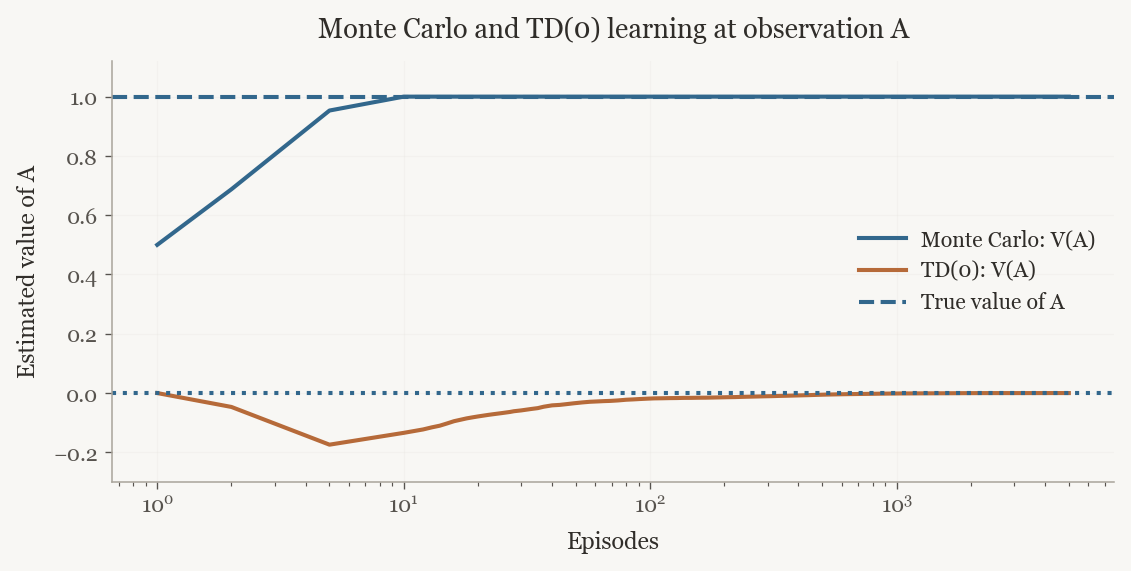

In [2]:
import matplotlib.pyplot as plt
plt.style.use('../mplstyle/blog.mplstyle')

fig, ax = plt.subplots(figsize=(8.2, 4.2))

ax.plot(checkpoints, mc_trace[A], label="Monte Carlo: V(A)")
ax.plot( checkpoints, td_trace[A], label="TD(0): V(A)")
ax.axhline(TRUE_VALUES[A], ls="--", label="True value of A")
ax.axhline(0, ls=":")
ax.set( xlabel="Episodes", ylabel="Estimated value of A",title="Monte Carlo and TD(0) learning at observation A")
ax.set_xscale("log")
ax.set_ylim(-0.30, 1.12)
ax.grid(alpha=0.18)
ax.legend(frameon=False, loc="center right")
fig.tight_layout()
plt.show()

MC reaches the correct value of $A$ as soon as it has observed a complete episode from $A$. TD, on the other hand, converges toward zero. The same issue occurs at $C$, where the true value is $-1$.

The final estimates make the difference clearer.

/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_65954/2394775149.py:21: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


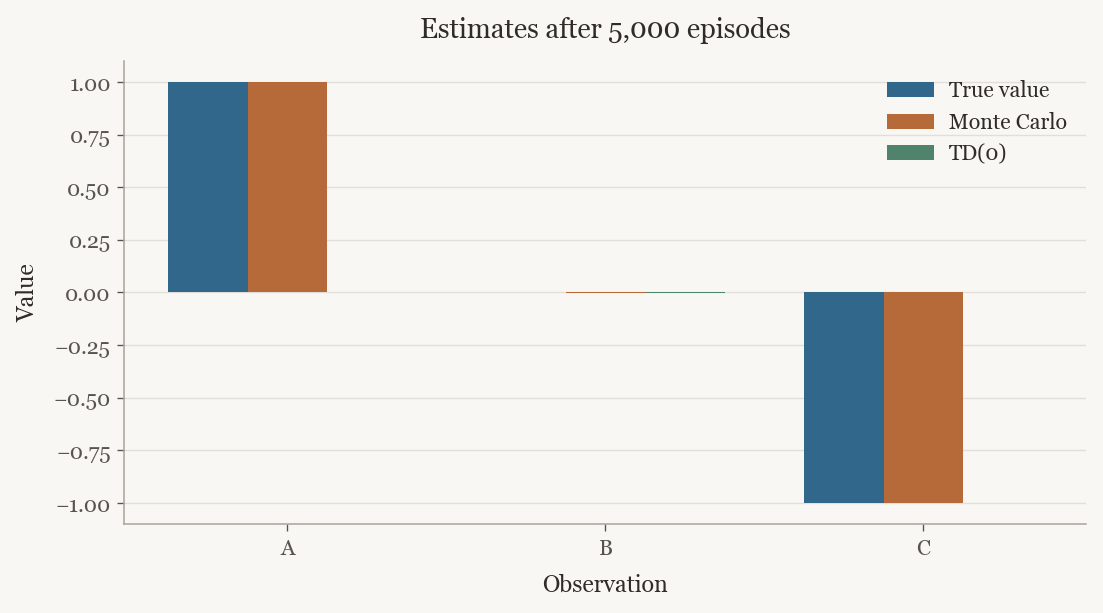

In [4]:
x = np.arange(len(OBSERVATIONS))
width = 0.25
plt.style.use('../mplstyle/blog.mplstyle')

true_values = [TRUE_VALUES[state] for state in OBSERVATIONS]
mc_estimates = [mc_trace[state][-1] for state in OBSERVATIONS]
td_estimates = [td_trace[state][-1] for state in OBSERVATIONS]

fig, ax = plt.subplots()

ax.bar(x - width, true_values, width, label="True value")
ax.bar(x, mc_estimates, width, label="Monte Carlo")
ax.bar(x + width, td_estimates, width, label="TD(0)")

ax.set_xticks(x, OBSERVATIONS)
ax.set_xlabel("Observation")
ax.set_ylabel("Value")
ax.set_title("Estimates after 5,000 episodes")
ax.legend()

fig.tight_layout()
plt.show()

## So Does Monte Carlo Solve Partial Observability?

No. Both methods still assign a single value to $B$. In this example, MC accurately estimates the values of $A$ and $C$ because it uses complete returns. However, this does not necessarily mean that MC outperforms TD in a partially observable environment. MC often has higher variance, must wait for the episode to end and is unsuitable for infinitely long episodes.

## Conclusion

MC and TD both calculate the same value for the aliased observation in our example. However, they disagree on the values of observations preceding it. This is because MC uses actual returns, while TD bootstraps from value estimates. Bootstrapping allows the information loss at $B$ to affect the value estimates of previous observations.

## References

1. Sutton, R. S., and Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, 2nd edition. Chapters 5–6.

<script src="https://utteranc.es/client.js"
        repo="novastar53/novastar53.github.io"
        issue-term="pathname"
        theme="github-light"
        crossorigin="anonymous"
        async>
</script>